# 02 – Speech-to-Text (STT) Benchmark: Coqui, Silero, VOSK & Whisper

In diesem Notebook werden vier lokale Open-Source-Spracherkennungssysteme anhand identischer deutscher und englischer Referenz-Audios evaluiert:

1. **Coqui STT** (ehemals Mozilla DeepSpeech, `.tflite` + KenLM-Scorer)
2. **Silero STT** (PyTorch Hub, CPU-optimierte Inferenz)
3. **VOSK** (Kaldi-basierte Offline-Erkennung)
4. **OpenAI Whisper (`base`)** (Transformer-Architektur, mehrsprachig)

**Bewertungskriterien (jeweils 0–5 Punkte):**
- **Textqualität:** Deutlichkeit, semantische Korrektheit, Interpunktion & Groß-/Kleinschreibung
- **Sprachverständnis:** Zahlen, Abkürzungen, Eigennamen, wörtliche Rede & Kontext
- **Technische Robustheit:** Geräuschresistenz, Sprechtempo, Setup- & Format-Anforderungen

In [4]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ref_path = Path("../data/reference_texts.json")
with ref_path.open("r", encoding="utf-8") as f:
    ref_data = json.load(f)

print("Referenzdaten geladen für Sprachen:", list(ref_data["texts"].keys()))

Referenzdaten geladen für Sprachen: ['de', 'en']


---
## 1. Coqui STT

**Setup & Besonderheiten:**
- Benötigt eine separate Umgebung mit `Python 3.10`, `numpy<2` und `stt==1.4.0` (TensorFlow 2.9).
- Audiodateien müssen vorab per `ffmpeg` explizit in **16 kHz, Mono, 16-Bit PCM WAV** konvertiert werden (`ffmpeg -i input.wav -ar 16000 -ac 1 -c:a pcm_s16le output.wav`).
- Zusätzlich zum akustischen Modell (`model.tflite`) muss pro Sprache ein externer KenLM-Scorer heruntergeladen werden.

### Referenz-Implementierung (Coqui STT)
```python
import wave
import numpy as np
import stt

model = stt.Model("models/model.tflite")
model.enableExternalScorer("models/model.scorer")

with wave.open("audio_16k_mono.wav", "rb") as wf:
    assert wf.getframerate() == 16000 and wf.getnchannels() == 1 and wf.getsampwidth() == 2
    audio_data = np.frombuffer(wf.readframes(wf.getnframes()), dtype=np.int16)

transcript = model.stt(audio_data)
```

### Aufgezeichnete Transkripte & Bewertung

- **Englisch (4.0 / 5):** *„on thursday march fourteenth twenty twenty four doctor emily carter arrived at conference room be three precisely at eight forty five a m ...“*  
  Inhaltlich weitgehend korrekt und flüssig, jedoch **komplett ohne Satzzeichen und Groß-/Kleinschreibung**; Zahlen werden ausgeschrieben (`ninety two point four per cent`), kleinere Wortfehler (`be three` statt `B3`, `insides` statt `insights`).
- **Deutsch (2.4 / 5):** *„am dienstag dem zwölften märz zweitausend vierundzwanzig traf doktor einer schneider um exakt acht uhr und fünfundvierzig minuten im konferenzen drei be des forschungs zentrums ein ...“*  
  Deutliche Worterkennungs- und Semantikfehler (z. B. *„kastrieren tieren“* statt *„kategorisierten“*, *„gartenseite“* statt *„Datensätze“*, *„buches“* statt *„Budgets“*, *„serviteli“* statt *„Server fiel“*) sowie fehlende Interpunktion.

---
## 2. Silero STT

**Setup & Besonderheiten:**
- Wird direkt über `torch.hub.load('snakers4/silero-models', model='silero_stt', ...)` geladen und ist für schnelle CPU-Inferenz optimiert.
- **Kompatibilitätsproblem (Deutsch):** Das vortrainierte deutsche TorchScript-Modell (`language='de'`, `jit_model='pt'`) löst unter aktuellen PyTorch-Versionen einen `RuntimeError` im TorchScript-Interpreter aus (`stft requires the return_complex parameter be given for real inputs`).

### Referenz-Implementierung (Silero STT)

```python
import torch

device = torch.device("cpu")
model, decoder, utils = torch.hub.load(
    repo_or_dir="snakers4/silero-models",
    model="silero_stt",
    language="en",
    device=device,
)
(read_batch, split_into_batches, read_audio, prepare_model_input) = utils

audio = read_audio("speech_english.wav", 16000)
input_data = prepare_model_input([audio], device=device)
transcript = decoder(model(input_data)[0])
```

### Aufgezeichnetes Transkript & Bewertung

- **Englisch (3.3 / 5):** *„on thursday march fourteenth twenty twenty four do emily carter arrived at conference room be three precisely at eight forty five a am ... emily remained comb ... most valuable insides“*  
  Hohe technische Stabilität auf der CPU, aber **keine Interpunktion oder Großschreibung**, ausgeschriebene Zahlen sowie einzelne Verhörer (`do` statt `Dr.`, `comb` statt `calm`, `insides` statt `insights`).
- **Deutsch:** Nicht produktiv einsetzbar aufgrund der TorchScript-Inkompatibilität mit modernen PyTorch-Releases.

---
## 3. VOSK

**Setup & Besonderheiten:**
- Vollständig offline-fähige Spracherkennung auf Kaldi-Basis mit geringem Ressourcenbedarf (`vosk-model-small-de-0.15` / `vosk-model-small-en-us-0.15`).
- Verarbeitet Audiodaten blockweise (`KaldiRecognizer`), liefert jedoch standardmäßig reinen Kleinschreibungs-Fließtext ohne Satzzeichen.

### Referenz-Implementierung (VOSK)

```python
import json
import soundfile as sf
from vosk import KaldiRecognizer, Model

model = Model("models/vosk-model-small-de-0.15")
audio, samplerate = sf.read("speech_german.wav", dtype="int16")
rec = KaldiRecognizer(model, samplerate)

chunks = []
for i in range(0, len(audio), 4000):
    if rec.AcceptWaveform(audio[i : i + 4000].tobytes()):
        chunks.append(json.loads(rec.Result()).get("text", ""))
chunks.append(json.loads(rec.FinalResult()).get("text", ""))
transcript = " ".join(chunks).strip()
```

### Aufgezeichnete Transkripte & Bewertung

- **Deutsch (3.7 / 5):** *„am dienstag dem zwölften märz zweitausendvierundzwanzig traf doktor anna schneider um exakt acht uhr und fünfundvierzig minuten im konferenzraum iii b des forschungszentrums ein ...“*  
  Deutlich bessere Worterkennung im Deutschen als Coqui (inkl. „Anna Schneider“ und „Budgets“), aber **keinerlei Interpunktion**, komplett kleingeschrieben und ausgeschriebene Zahlen.
- **Englisch (3.7 / 5):** *„on thursday march fourteenth twenty twenty four doctor emily carter arrived at conference room be three precisely at eight forty five am ...“*  
  Inhaltlich sehr zuverlässig und schnell, jedoch ebenfalls ohne Satzgrenzen oder Großschreibung.

---
## 4. OpenAI Whisper (`base`)

**Setup & Besonderheiten:**
- Ein einziges multilinguales Modell (`base`) deckt Deutsch, Englisch und über 50 weitere Sprachen inklusive automatischer Spracherkennung ab.
- Keine manuelle WAV-Vorkonvertierung notwendig (interne Resampling-Pipeline über `ffmpeg`).
- Generiert automatisch **Satzzeichen, Groß-/Kleinschreibung, Datumsformate, Prozentzeichen und Währungssymbole** – eine entscheidende Voraussetzung für nachgelagerte NLU-Modelle (spaCy NER & Satz-Segmentierung).

### Referenz-Implementierung (OpenAI Whisper)
```python
import whisper

model = whisper.load_model("base")
result = model.transcribe("speech_german.wav")
print(result["language"], result["text"])
```

### Aufgezeichnete Transkripte & Bewertung

- **Englisch (4.6 / 5):** *„On Thursday, March 14, 2024, Dr. Emily Carter arrived at conference room B3 precisely at 8.45am. Good morning, everyone, she began warmly. ... 1,278 entries ... 92.4% ... $950.“*  
  Nahezu fehlerfreie Worterkennung, korrekte Formatierung von Eigennamen, Zahlen, Prozenten und Geldbeträgen sowie sinnvolle Satzzeichen.
- **Deutsch (3.0 / 5 – klarer Spitzenreiter bei Struktur & Interpunktion):** *„Am Dienstag dem 12. März 2024, traf Dr. Anna Schneider um exakt 8 Uhr und 45 Minuten im Konferenzraum 3B des Forschungszentrums ein. ... 1278 Datensätze ... 92,4%. ...“*  
  Erkennt im Gegensatz zu Coqui, Silero und VOSK Satzgrenzen, Großschreibung und Zahlenformate (`12. März 2024`, `3B`, `92,4%`). Einzelne kleinere Fehler im Deutschen (*„Büges“* statt *„Budgets“*, *„viel“* statt *„fiel“*, fehlende Anführungszeichen bei direkter Rede).

---
## 5. Quantitativer Gesamtvergleich & Visualisierung

,Modell,Score EN (0-5),Score DE (0-5),Interpunktion & Case,Zahlenformat,Status
0,Coqui STT,4.0,2.4,Nein,Ausgeschrieben,Veraltete Abhängigkeiten (Python 3.10 / TF 2.9)
1,Silero STT,3.3,0.0,Nein,Ausgeschrieben,DE-Modell inkompatibel mit aktuellem PyTorch
2,VOSK (small),3.7,3.7,Nein,Ausgeschrieben,"Schnell & offline, aber reiner Fließtext ohne ..."
3,OpenAI Whisper (base),4.6,3.0,Ja,"Numerisch (12. März, 92,4%, $950)",Produktiv übernommen (src/stt_whisper.py)


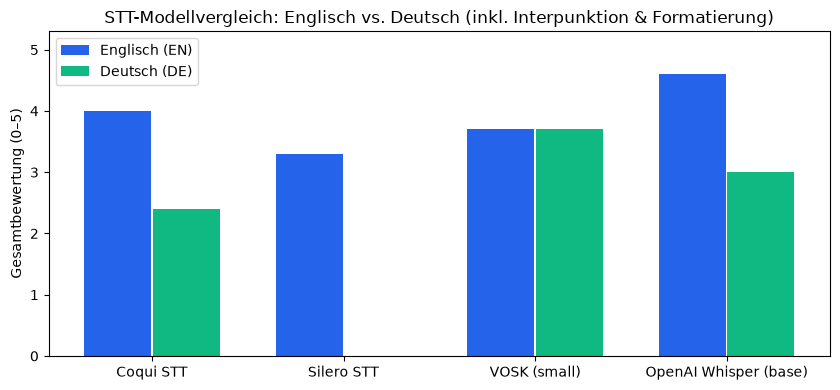

In [5]:
benchmark_data = [
    {
        "Modell": "Coqui STT",
        "Score EN (0-5)": 4.0,
        "Score DE (0-5)": 2.4,
        "Interpunktion & Case": "Nein",
        "Zahlenformat": "Ausgeschrieben",
        "Status": "Veraltete Abhängigkeiten (Python 3.10 / TF 2.9)",
    },
    {
        "Modell": "Silero STT",
        "Score EN (0-5)": 3.3,
        "Score DE (0-5)": 0.0,
        "Interpunktion & Case": "Nein",
        "Zahlenformat": "Ausgeschrieben",
        "Status": "DE-Modell inkompatibel mit aktuellem PyTorch",
    },
    {
        "Modell": "VOSK (small)",
        "Score EN (0-5)": 3.7,
        "Score DE (0-5)": 3.7,
        "Interpunktion & Case": "Nein",
        "Zahlenformat": "Ausgeschrieben",
        "Status": "Schnell & offline, aber reiner Fließtext ohne Satzzeichen",
    },
    {
        "Modell": "OpenAI Whisper (base)",
        "Score EN (0-5)": 4.6,
        "Score DE (0-5)": 3.0,
        "Interpunktion & Case": "Ja",
        "Zahlenformat": "Numerisch (12. März, 92,4%, $950)",
        "Status": "Produktiv übernommen (src/stt_whisper.py)",
    },
]

df_stt = pd.DataFrame(benchmark_data)
display(df_stt)

# Balkendiagramm der Bewertungen (EN vs. DE)
fig, ax = plt.subplots(figsize=(8.5, 4))
x = range(len(df_stt))
ax.bar([i - 0.18 for i in x], df_stt["Score EN (0-5)"], width=0.35, label="Englisch (EN)", color="#2563eb")
ax.bar([i + 0.18 for i in x], df_stt["Score DE (0-5)"], width=0.35, label="Deutsch (DE)", color="#10b981")

ax.set_xticks(list(x))
ax.set_xticklabels(df_stt["Modell"])
ax.set_ylim(0, 5.3)
ax.set_ylabel("Gesamtbewertung (0–5)")
ax.set_title("STT-Modellvergleich: Englisch vs. Deutsch (inkl. Interpunktion & Formatierung)")
ax.legend()
plt.tight_layout()
plt.show()

### Optionaler Live-Test mit der produktiven Whisper-Komponente (`src/stt_whisper.py`)

Prüft die produktive Implementierung aus `src/stt_whisper.py` direkt anhand der Referenz-Audios (`../data/sample_audio/sample_de.wav` und `sample_en.wav`).

In [6]:
import sys

sys.path.append("..")
from src.stt_whisper import transcribe_audio

sample_dir = Path("../data/sample_audio")
audio_files = sorted(sample_dir.glob("sample_*.wav")) if sample_dir.exists() else []

if not audio_files:
    print(
        "Hinweis: Keine Referenz-Audios unter '../data/sample_audio/sample_*.wav' gefunden.\n"
        "Erzeuge sie einmalig im Projekt-Root mit: python scripts/generate_sample_audio.py"
    )
else:
    for audio_path in audio_files:
        res = transcribe_audio(audio_path, model_size="base")
        print(f"Datei: {audio_path.name} | Sprache: {res['language']} | Dauer: {res['duration_sec']}s")
        print("Transkript:", res["text"], "\n")

Datei: sample_de.wav | Sprache: de | Dauer: 4.1808s
Transkript: Am Dienstag dem 12. März 2004, traf Dr. Anna Schneider um exakt 8 Uhr und 45 Minuten im Konferenzraum 3B des Forschungszentrums ein. Guten Morgen, meine Damen und Herren, begann Sie freundlich. Ich freue mich, Ihnen heute die neuesten Ergebnisse unserer Kai Studie präsentieren zu dürfen. Die Analyse umfasster 1278 Datensätze, verteilt auf 5 Kategorien und zeigt da eine durchschnittliche Genauigkeit von 92,4%. Besonders interessant war der Anstieg der Nutzerzahl um 15% im Vergleich zum Vorjahr, trotz eines Bügels von nur 950. Doch dann kam eine überraschende Wendung, der Server viel plötzlich aus. Was ist passiert, rief jemand panisch. Anna blieb ruhig. Keine Sorge, wir haben ein Deck-Up-System. 

Datei: sample_en.wav | Sprache: en | Dauer: 3.8617s
Transkript: On Thursday, March 14, 2024, Dr. Emily Carter arrived at conference room B3 precisely at 8.45am. Good morning, everyone, she began warmly. Today, I'm excited to share

---
## 6. Architekturentscheidung für die Pipeline

**OpenAI Whisper (`base`)** wurde als produktives STT-Backend (`src/stt_whisper.py`) gewählt:
1. **NLU-Kompatibilität:** Alle drei Alternativen (Coqui, Silero, VOSK) liefern unformatierte Kleinschreibung ohne Punkt und Komma. Ohne Satzzeichen und Großschreibung sinkt die Erkennungsrate von **spaCy NER** drastisch, und eine satzweise **Zero-Shot Intent-Klassifikation** ist ohne zusätzliche *Punctuation-Restoration*-Modelle nicht zuverlässig möglich.
2. **Einheitliches Setup:** Ein einzelnes Modell deckt Deutsch und Englisch samt automatischer Spracherkennung ab und läuft ohne veraltete Python-/PyTorch-Abhängigkeiten.